# Full interaction (Heisenberg + RKKY)

In [ ]:
using Pkg; Pkg.update()

using MX2RKKY.montecarlo
using MX2RKKY.lattice
using MX2RKKY.observables

using LinearAlgebra: norm
using Statistics: mean, std
using HDF5
using CSV
using DataFrames

using PyPlot; const plt = PyPlot;

## Analyse data

In [3]:
function collect_from_h5(ar, name)
    T_range = ar["params/T_range"][]
    return [ar["/T$(T)/$(name)"][] for T in T_range if "T$(T)" in keys(ar)] 
end

function make_observables_df(ar)
    params = read(ar, "params")
    L = params["L"][]
    T_range = [T for T in params["T_range"] if "T$(T)" in keys(ar)]
    β_range = 1.0 ./ T_range

    df = DataFrame("T" => T_range)

    metadata!(df, "L", L, style=:note)
    metadata!(df, "Vpar", params["Vpar"], style=:note)
    metadata!(df, "lambda", params["lambda"], style=:note)
    
    # Energy
    E = collect_from_h5(ar, "E")
    insertcols!(df, "E_avg" => avg_energy.(E) / L^2,
                    "E_var" => var_energy.(E) / L^2)
    colmetadata!(df, :E_avg, "plot", true, style=:note)
    colmetadata!(df, :E_avg, "errors", :E_var, style=:note)
    colmetadata!(df, :E_avg, "ylabel", raw"$\langle E\rangle$, per atom", style=:note)
    colmetadata!(df, :E_var, "plot", false, style=:note)
    
    # Specific heat
    insertcols!(df, "cV" => specific_heat.(E, β_range) / L^2)
    colmetadata!(df, :cV, "plot", true, style=:note)
    colmetadata!(df, :cV, "ylabel", raw"$c_V$, per atom", style=:note)
    
    # Average chirality
    χ = collect_from_h5(ar, "chi")
    insertcols!(df, "chi_avg" => avg_chirality.(χ),
                    "chi_var" => var_chirality.(χ))
    colmetadata!(df, :chi_avg, "plot", true, style=:note)
    colmetadata!(df, :chi_avg, "errors", :chi_var, style=:note)
    colmetadata!(df, :chi_avg, "ylabel", raw"$\langle\chi\rangle$", style=:note)
    colmetadata!(df, :chi_var, "plot", false, style=:note)
    
    # Chirality susceptibility
    insertcols!(df, "susc_chi" => susc_chirality.(χ, L^2, β_range) / L^2)
    colmetadata!(df, :susc_chi, "plot", true, style=:note)
    colmetadata!(df, :susc_chi, "ylabel", raw"$\chi_c = \langle(\delta\chi)^2\rangle / T$, per atom", style=:note)
    colmetadata!(df, :susc_chi, "ylim", (0.0, 0.02), style=:note)
    
    # Chirality Binder cumulant
    insertcols!(df, "binder_chi" => binder_chirality.(χ))
    colmetadata!(df, :binder_chi, "plot", true, style=:note)
    colmetadata!(df, :binder_chi, "ylabel", raw"$g_c$", style=:note)
        
    # Chirality correlation length
    χ_at_q_min = collect_from_h5(ar, "chi_at_q_min")
    insertcols!(df, "corr_length_chi" => abs.(corr_length_chirality.(χ, χ_at_q_min, L)))
    colmetadata!(df, :corr_length_chi, "plot", true, style=:note)
    colmetadata!(df, :corr_length_chi, "ylabel", raw"$\xi_c$", style=:note)
    colmetadata!(df, :corr_length_chi, "ylim", (0.0, 50.0), style=:note)
        
    # Average magnetization at K-point
    m_at_K = collect_from_h5(ar, "m_at_K")
    m_at_K_avg = [mean(m, dims=2) for m in m_at_K]
    dm_at_K = [m .- m_avg for (m, m_avg) in zip(m_at_K, m_at_K_avg)]
    m_at_K_var = [sqrt(mean(mapslices(norm, dm, dims=1) .^ 2)) for dm in dm_at_K] 
    insertcols!(df, "m_abs_at_K_avg" => norm.(m_at_K_avg),
                    "m_abs_at_K_var" => m_at_K_var)
    colmetadata!(df, :m_abs_at_K_avg, "plot", true, style=:note)
    colmetadata!(df, :m_abs_at_K_avg, "errors", :m_abs_at_K_var, style=:note)
    colmetadata!(df, :m_abs_at_K_avg, "ylabel", raw"$|\langle\mathbf{m}(\mathbf{K})\rangle|$", style=:note)
    colmetadata!(df, :m_abs_at_K_var, "plot", false, style=:note)
   
    # Magnetization at K-point: susceptibility
    insertcols!(df, "susc_spin_K" => susc_spin_K.(m_at_K, L^2, β_range) / L^2)
    colmetadata!(df, :susc_spin_K, "plot", true, style=:note)
    colmetadata!(df, :susc_spin_K, "ylabel", raw"$\chi_s = \langle(\delta\vec{m}(\vec{K}))^2\rangle / T$", style=:note)
    colmetadata!(df, :susc_spin_K, "ylim", (0.0, 0.5), style=:note)
    
    # Magnetization at K-point: Binder cumulant
    insertcols!(df, "binder_spin_K" => binder_spin_K.(m_at_K))
    colmetadata!(df, :binder_spin_K, "plot", true, style=:note)
    colmetadata!(df, :binder_spin_K, "ylabel", raw"$g_s$", style=:note)
    
    # Magnetization at K-point: Correlation length
    m_at_K_q_min = collect_from_h5(ar, "m_at_K_q_min")
    insertcols!(df, "corr_length_spin_K" => abs.(corr_length_spin_K.(m_at_K, m_at_K_q_min, L)))
    colmetadata!(df, :corr_length_spin_K, "plot", true, style=:note)
    colmetadata!(df, :corr_length_spin_K, "ylabel", raw"$\xi_s$", style=:note)
    colmetadata!(df, :corr_length_spin_K, "ylim", (0.0, 50.0), style=:note)
    
    return df
end

make_observables_df (generic function with 1 method)

## Plot results

In [8]:
function plot_observables(dfs::Vector{DataFrame}; figsize=(7, 20), pdfname)
    all_cols = union(keys.(eachcol.(dfs))...)
    plot_col = name -> (name != :T) && any([colmetadata(df, name, "plot") for df in dfs])    
    nplots = count(plot_col, all_cols)

    fig = plt.figure(figsize=figsize)
    gs = plt.matplotlib.gridspec.GridSpec(nplots, 1, hspace=0)
    plt_i = 1
    ax = plt.subplot(gs[1])
    
    for name in all_cols
        !plot_col(name) && continue

        if plt_i > 1
            ax = plt.subplot(gs[plt_i], sharex=ax)
        end
        ax.grid(axis="x", which="both")

        for df in dfs
            L = metadata(df, "L")
            V = metadata(df, "Vpar")
            lambda = metadata(df, "lambda")
            label = "\$V=$(V), k_F a_0 = $(lambda), L=$(L)\$"
            
            if "errors" in keys(colmetadata(df, name))
                errors = df[!, colmetadata(df, name, "errors")]
                ax.errorbar(df.T, df[!, name], yerr=errors, lw=0.7, label=label)
            else
                ax.plot(df.T, df[!, name], lw=0.7, label=label)
            end
            if "ylim" in keys(colmetadata(df, name))
                ax.set_ylim(colmetadata(df, name, "ylim"))
            end
            ax.set_ylabel(colmetadata(df, name, "ylabel"))
        end
        
        plt.legend()
        
        if plt_i < nplots
            plt.setp(ax.get_xticklabels(), visible=false)
        end
        plt_i += 1
    end

    # General plot setup
    ax.set_xlim((first(dfs[1].T), last(dfs[1].T)))
    ax.set_xlabel(raw"$T/J$")
    ax.minorticks_on()
    plt.tight_layout()
    plt.show()
    fig.savefig(pdfname)
end

plot_observables (generic function with 1 method)

## Export results

In [5]:
function export_observables(df::DataFrame)
    L = metadata(df, "L")
    V = metadata(df, "Vpar")
    lambda = metadata(df, "lambda")
    CSV.write("RKKY_T_scan_V$(V)_lambda$(lambda)_L$(L).dat", df, delim="    ");
end

export_observables (generic function with 1 method)

In [39]:
df0_24 = make_observables_df(h5open("../../RKKY_temperature_scan/RKKY_T_scan_Vpar0.0_L24.h5", "r"));
df1_24 = make_observables_df(h5open("../../RKKY_temperature_scan/RKKY_T_scan_Vpar0.001_L24.h5", "r"));
df2_24 = make_observables_df(h5open("../../RKKY_temperature_scan/RKKY_T_scan_Vpar0.002_L24.h5", "r"));

sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


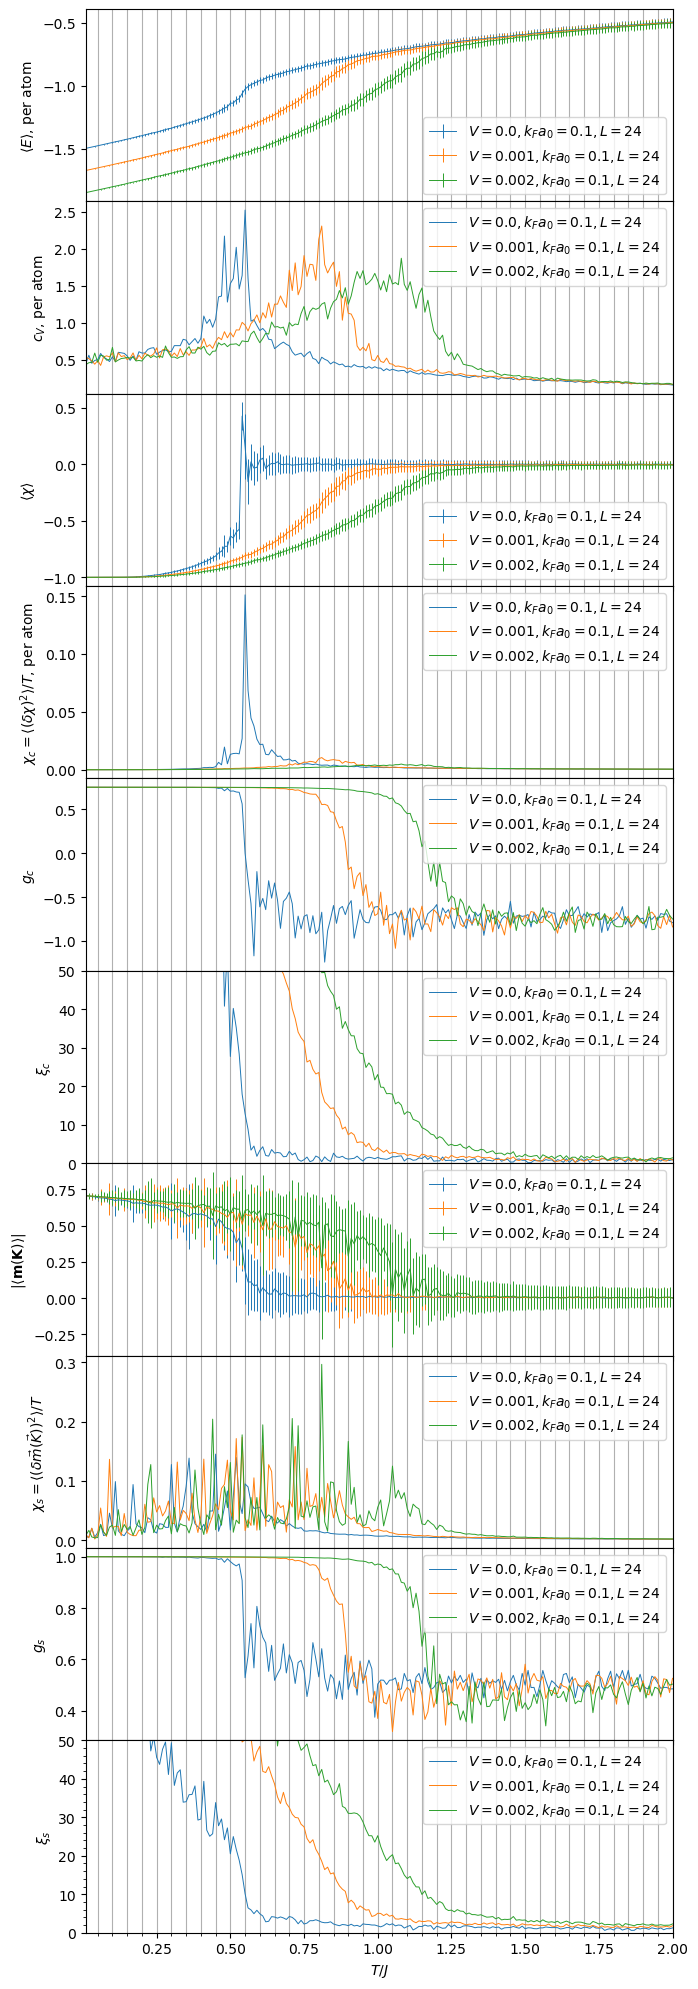

In [42]:
plot_observables([df0_24, df1_24, df2_24], pdfname="rkky_V_0_0.001_0.002_L24.pdf")
export_observables(df0_24);
export_observables(df1_24);
export_observables(df2_24);

In [6]:
df1_9 = make_observables_df(h5open("../../RKKY_temperature_scan/RKKY_T_scan_Vpar0.001_L9.h5", "r"));
df1_15 = make_observables_df(h5open("../../RKKY_temperature_scan/RKKY_T_scan_Vpar0.001_L15.h5", "r"));
df1_24 = make_observables_df(h5open("../../RKKY_temperature_scan/RKKY_T_scan_Vpar0.001_L24.h5", "r"));
df1_27 = make_observables_df(h5open("../../RKKY_temperature_scan/RKKY_T_scan_Vpar0.001_L27.h5", "r"));
df1_30 = make_observables_df(h5open("../../RKKY_temperature_scan/RKKY_T_scan_Vpar0.001_L30.h5", "r"));

sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


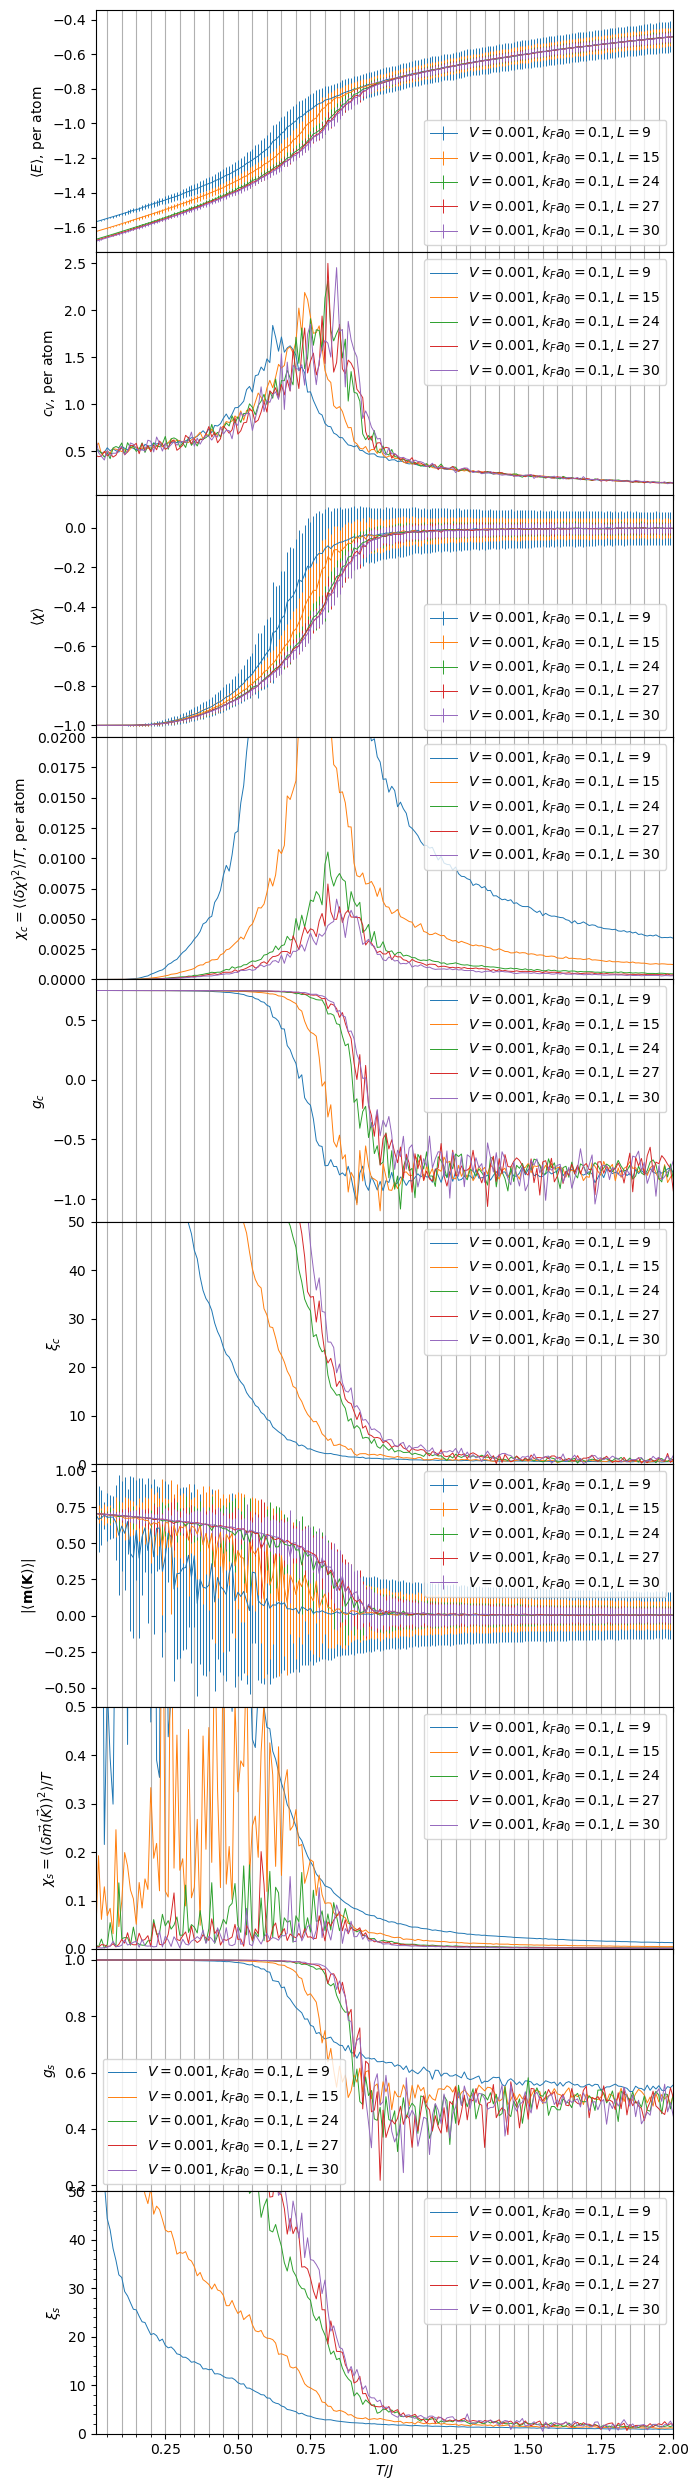

In [9]:
plot_observables([df1_9, df1_15, df1_24, df1_27, df1_30], pdfname="rkky_V_0.001_L9_15_24_27_30.pdf", figsize=(7, 25))
export_observables(df1_9);
export_observables(df1_15);
export_observables(df1_24);
export_observables(df1_27);
export_observables(df1_30);